# 學生表現因素多元線性回歸分析 (Student Performance Factors Analysis)
## 遵循 CRISP-DM 流程之資料理解、防洩漏前處理、特徵選擇、95% 預測區間與統計診斷

- **研究課程**：機器學習與統計數據分析
- **主要資料集**：Kaggle Student Performance Factors (`lainguyn123/student-performance-factors`)
- **目標變數**：`Exam_Score` (0～100 連續數值)
- **分析方法**：Scikit-learn LinearRegression、Statsmodels OLS、5 折交叉驗證、五大回歸假設檢定


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# 設定繪圖風格
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.autolayout"] = True

# 加入專案根目錄至 sys.path
sys.path.insert(0, os.path.abspath(".."))

from src.data_loader import load_student_performance
from src.preprocessing import prepare_dataset
from src.feature_selection import run_feature_selection_comparison
from src.prediction_intervals import OLSPredictionModel
from src.statistical_tests import diagnose_regression_assumptions


## 第一與第二階段：商業理解 (Business Understanding) 與資料探索 (Data Understanding)
### 1.1 研究背景與因果限制揭露
多元線性回歸估計之迴歸係數為在控制其他變數下的**統計邊際關聯度**。**「關聯性不代表因果關係 (Correlation is NOT Causation)」**。在缺乏外生隨機實驗 (RCT) 之前提下，分析結果僅代表預測關聯，不可逕行推論為因果介入政策。

### 1.2 載入資料與檢視結構
載入 Kaggle Student Performance Factors 資料集（6,607 筆樣本，19 個原始輸入特徵 + 1 個目標變數 `Exam_Score`）。


In [2]:
df = load_student_performance()
print(f"資料集維度：{df.shape[0]} 筆樣本，{df.shape[1]} 個欄位")
print("各欄位遺漏值檢視：")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()


資料集維度：6607 筆樣本，20 個欄位
各欄位遺漏值檢視：
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Exam_Score 敘述統計：
count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64


C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32771 (\N{CJK UNIFIED IDEOGRAPH-8003}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 35430 (\N{CJK UNIFIED IDEOGRAPH-8A66}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32318 (\N{CJK UNIFIED IDEOGRAPH-7E3E}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-pack

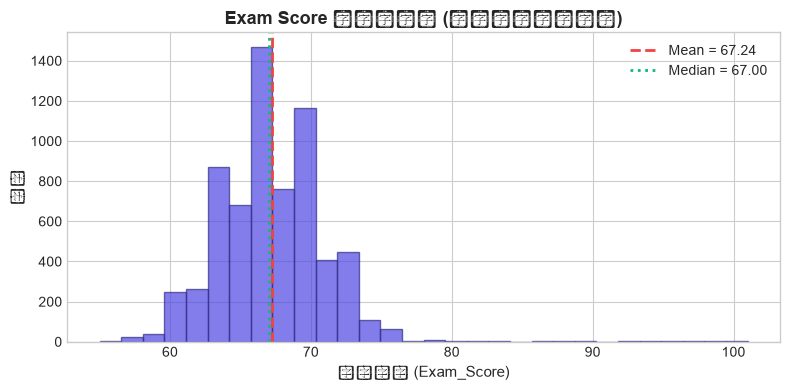

In [3]:
# 目標變數 Exam_Score 敘述統計與分佈圖
print("Exam_Score 敘述統計：")
print(df["Exam_Score"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Exam_Score"], bins=30, color="#4F46E5", alpha=0.7, edgecolor="#312E81")
ax.axvline(df["Exam_Score"].mean(), color="#EF4444", linestyle="--", linewidth=2, label=f"Mean = {df['Exam_Score'].mean():.2f}")
ax.axvline(df["Exam_Score"].median(), color="#10B981", linestyle=":", linewidth=2, label=f"Median = {df['Exam_Score'].median():.2f}")
ax.set_title("Exam Score 分佈直方圖 (近似常態對稱分佈)", fontsize=13, fontweight="bold")
ax.set_xlabel("考試成績 (Exam_Score)", fontsize=11)
ax.set_ylabel("頻率", fontsize=11)
ax.legend()
plt.show()


連續變數與 Exam_Score 相關矩陣：
                   Exam_Score
Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022


C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 36899 (\N{CJK UNIFIED IDEOGRAPH-9023}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32396 (\N{CJK UNIFIED IDEOGRAPH-7E8C}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-pack

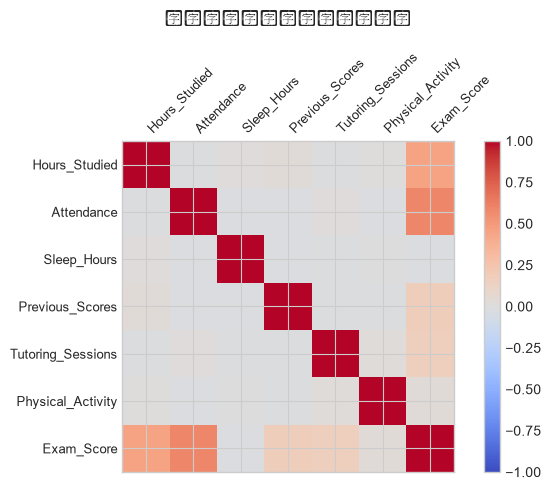

In [4]:
# 連續數值特徵與 Exam_Score 相關係數檢視
num_cols = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores", "Tutoring_Sessions", "Physical_Activity", "Exam_Score"]
corr_mat = df[num_cols].corr()
print("連續變數與 Exam_Score 相關矩陣：")
print(corr_mat["Exam_Score"].sort_values(ascending=False).to_frame())

fig, ax = plt.subplots(figsize=(7, 5))
cax = ax.matshow(corr_mat, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(cax)
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="left", fontsize=9)
ax.set_yticklabels(num_cols, fontsize=9)
ax.set_title("連續數值變數相關係數熱力圖", fontsize=12, fontweight="bold", pad=20)
plt.show()


## 第三階段：資料準備 (Data Preparation) — 嚴格防範資料洩漏之管線
1. **切分優先**：先執行 80/20 訓練/測試切分 (`random_state=42`)，徹底隔離測試集。
2. **無洩漏轉換**：`ColumnTransformer` 僅在訓練集 `.fit()`，中位數/眾數補值與標準化參數完全來自訓練集。
3. **One-Hot Encoding 基準組**：設定 `drop='first'`，杜絕虛擬變數陷阱 (Dummy Variable Trap)。
4. 原始 19 個輸入特徵經編碼後擴增為 **27 個數值型設計特徵**。


In [5]:
artifacts = prepare_dataset(
    df=df,
    target_col="Exam_Score",
    test_size=0.20,
    random_state=42,
)
print(f"訓練集樣本數：{len(artifacts.X_train_proc)}")
print(f"測試集樣本數：{len(artifacts.X_test_proc)}")
print(f"編碼後特徵數：{len(artifacts.feature_names_out)}")
print("編碼後特徵清單：", artifacts.feature_names_out)


訓練集樣本數：5285
測試集樣本數：1322
編碼後特徵數：27
編碼後特徵清單： ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_Yes', 'Motivation_Level_Low', 'Motivation_Level_Medium', 'Internet_Access_Yes', 'Family_Income_Low', 'Family_Income_Medium', 'Teacher_Quality_Low', 'Teacher_Quality_Medium', 'School_Type_Public', 'Peer_Influence_Neutral', 'Peer_Influence_Positive', 'Learning_Disabilities_Yes', 'Parental_Education_Level_High School', 'Parental_Education_Level_Postgraduate', 'Distance_from_Home_Moderate', 'Distance_from_Home_Near', 'Gender_Male']


## 第四階段：特徵選擇與模型建立 (Modeling & Feature Selection)
系統性比較 **全特徵基準 (Baseline)** 與 **5 種主流特徵選擇方法**：
- **Baseline (All Features)**：保留全部 27 個特徵
- **SelectKBest (Filter)**：單變量 F 檢定 ($f_{\text{regression}}$)，取 $K=5$
- **RFE (Wrapper)**：遞迴剔除權重最小特徵，取 $K=5$
- **SFS Forward (Wrapper)**：循序前向貪婪挑選最佳子集，取 $K=5$
- **Lasso Selection (Embedded)**：LassoCV 尋求最優 $\alpha$
- **Permutation Importance (Model-based)**：泛化排列重要度，取 $K=5$


In [6]:
summary_df, results_map, models_map = run_feature_selection_comparison(
    X_train=artifacts.X_train_proc,
    y_train=artifacts.y_train,
    X_test=artifacts.X_test_proc,
    y_test=artifacts.y_test,
    k=5,
    cv_folds=5,
    random_state=42,
    fast_mode=False,
)
print("=== 5 種特徵選擇方法之效能比較表 ===")
summary_df[["Method", "Features", "R2", "Adj_R2", "RMSE", "MAE", "Train_R2", "CV_R2_Mean", "Time_Sec"]]


=== 5 種特徵選擇方法之效能比較表 ===


,Method,Features,R2,Adj_R2,RMSE,MAE,Train_R2,CV_R2_Mean,Time_Sec
0,Baseline (All Features),27,0.769650,0.764843,1.804445,0.452392,0.717314,0.715585,0.102
1,Lasso Selection (Embedded),27,0.769650,0.764843,1.804445,0.452392,0.717314,0.715585,0.151
2,Permutation Importance,5,0.666460,0.665193,2.171314,1.190192,0.597603,0.598156,0.644
3,SelectKBest (Filter),5,0.664693,0.663419,2.177060,1.174931,0.605658,0.606164,0.067
4,SFS Forward (Wrapper),5,0.664693,0.663419,2.177060,1.174931,0.605658,0.606164,19.875
5,RFE (Wrapper),5,0.645730,0.644384,2.237773,1.266747,0.580982,0.581391,0.176


C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 21028 (\N{CJK UNIFIED IDEOGRAPH-5224}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20418 (\N{CJK UNIFIED IDEOGRAPH-4FC2}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-pack

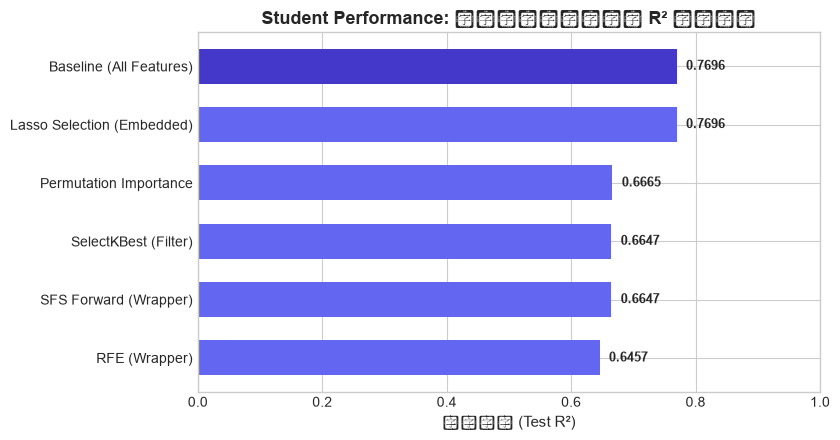

In [7]:
# 視覺化比較各方法之測試集 R²
fig, ax = plt.subplots(figsize=(8.5, 4.5))
methods = summary_df["Method"].tolist()
r2_vals = summary_df["R2"].tolist()
colors = ["#4338CA" if "Baseline" in m else "#6366F1" for m in methods]
bars = ax.barh(methods, r2_vals, color=colors, height=0.6)
ax.invert_yaxis()
ax.set_xlim(0, 1.0)
ax.set_title("Student Performance: 特徵選擇方法測試集 R² 績效比較", fontsize=13, fontweight="bold")
ax.set_xlabel("判定係數 (Test R²)", fontsize=11)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.015, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=9.5, fontweight="bold")
plt.show()


In [8]:
# 檢視各方法挑選出的特徵子集
for method, res in results_map.items():
    print(f"[{method}] (挑選 {len(res.selected_features)} 個特徵):")
    print(f"  -> {', '.join(res.selected_features)}")
    if res.details and "alpha" in res.details:
        print(f"  -> 最優 alpha = {res.details['alpha']:.6f}, 非零係數特徵數 = {res.details['nonzero_count']}")


[Baseline (All Features)] (挑選 27 個特徵):
  -> Hours_Studied, Attendance, Sleep_Hours, Previous_Scores, Tutoring_Sessions, Physical_Activity, Parental_Involvement_Low, Parental_Involvement_Medium, Access_to_Resources_Low, Access_to_Resources_Medium, Extracurricular_Activities_Yes, Motivation_Level_Low, Motivation_Level_Medium, Internet_Access_Yes, Family_Income_Low, Family_Income_Medium, Teacher_Quality_Low, Teacher_Quality_Medium, School_Type_Public, Peer_Influence_Neutral, Peer_Influence_Positive, Learning_Disabilities_Yes, Parental_Education_Level_High School, Parental_Education_Level_Postgraduate, Distance_from_Home_Moderate, Distance_from_Home_Near, Gender_Male
[SelectKBest (Filter)] (挑選 5 個特徵):
  -> Hours_Studied, Attendance, Previous_Scores, Tutoring_Sessions, Access_to_Resources_Low
[RFE (Wrapper)] (挑選 5 個特徵):
  -> Hours_Studied, Attendance, Parental_Involvement_Low, Parental_Involvement_Medium, Access_to_Resources_Low
[SFS Forward (Wrapper)] (挑選 5 個特徵):
  -> Hours_Studied, Attend

## 第五階段：模型評估 (Evaluation)、95% 預測區間推論與五大假設診斷
### 5.1 Statsmodels OLS 95% 信賴區間 (CI) vs. 95% 預測區間 (PI)
- **95% Confidence Interval (母體均值信賴區間)**：描述「平均反應期望值」$E[Y|X]$ 的估計不確定度。
- **95% Prediction Interval (單一觀測值預測區間)**：描述「未來特定單一位新學生」實際考分的落點，必定涵蓋隨機誤差 $\sigma^2$。


In [9]:
ols_model = OLSPredictionModel()
ols_model.fit(artifacts.X_train_proc, artifacts.y_train)
pi_df = ols_model.predict_intervals(artifacts.X_test_proc, alpha=0.05)

ci_mean_width = (pi_df["mean_ci_upper"] - pi_df["mean_ci_lower"]).mean()
pi_mean_width = (pi_df["obs_ci_upper"] - pi_df["obs_ci_lower"]).mean()
y_test = artifacts.y_test.values
ci_cov = np.mean((y_test >= pi_df["mean_ci_lower"].values) & (y_test <= pi_df["mean_ci_upper"].values)) * 100
pi_cov = np.mean((y_test >= pi_df["obs_ci_lower"].values) & (y_test <= pi_df["obs_ci_upper"].values)) * 100

print(f"95% CI (母體均值) 平均區間寬度：{ci_mean_width:.4f} 分，測試集涵蓋率：{ci_cov:.2f}%")
print(f"95% PI (單一觀測值) 平均區間寬度：{pi_mean_width:.4f} 分，測試集涵蓋率：{pi_cov:.2f}%")
print(f"PI 平均寬度為 CI 的 {pi_mean_width / ci_mean_width:.1f} 倍！")


95% CI (母體均值) 平均區間寬度：0.5913 分，測試集涵蓋率：49.85%
95% PI (單一觀測值) 平均區間寬度：8.2190 分，測試集涵蓋率：99.47%
PI 平均寬度為 CI 的 13.9 倍！


C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 35430 (\N{CJK UNIFIED IDEOGRAPH-8A66}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 27171 (\N{CJK UNIFIED IDEOGRAPH-6A23}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sam98\AppData\Local\Python\pythoncore-3.14-64\Lib\site-pack

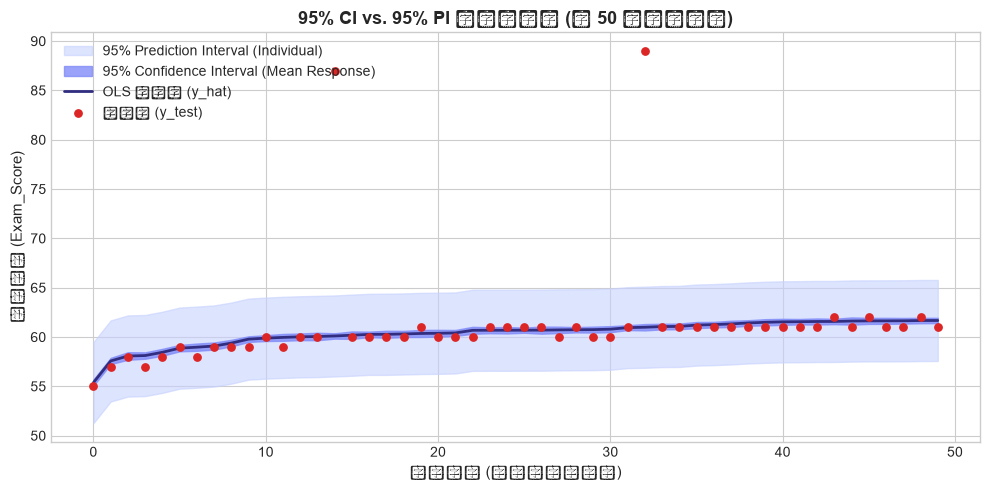

In [10]:
# 繪製前 50 筆排序測試樣本之 CI vs PI 帶狀圖
sort_idx = np.argsort(pi_df["mean"].values)[:50]
x_axis = np.arange(len(sort_idx))

plt.figure(figsize=(10, 5))
plt.fill_between(x_axis, pi_df["obs_ci_lower"].values[sort_idx], pi_df["obs_ci_upper"].values[sort_idx], color="#C7D2FE", alpha=0.6, label="95% Prediction Interval (Individual)")
plt.fill_between(x_axis, pi_df["mean_ci_lower"].values[sort_idx], pi_df["mean_ci_upper"].values[sort_idx], color="#818CF8", alpha=0.8, label="95% Confidence Interval (Mean Response)")
plt.plot(x_axis, pi_df["mean"].values[sort_idx], color="#312E81", linewidth=2, label="OLS 擬合值 (y_hat)")
plt.scatter(x_axis, artifacts.y_test.values[sort_idx], color="#DC2626", s=28, zorder=5, label="真實值 (y_test)")
plt.title("95% CI vs. 95% PI 實證視覺化 (前 50 筆測試樣本)", fontsize=13, fontweight="bold")
plt.xlabel("測試樣本 (依預測成績排序)", fontsize=11)
plt.ylabel("考試成績 (Exam_Score)", fontsize=11)
plt.legend(loc="upper left")
plt.show()


In [11]:
# 執行線性回歸五大基本假設診斷
diagnostics = diagnose_regression_assumptions(ols_model.ols_results, artifacts.X_train_proc, artifacts.y_train)
for k, v in diagnostics.items():
    print(f"=== {v['diagnostic']} ===")
    print(f"  評估方法: {v['method']}")
    print(f"  統計指標: {v.get('metric_name')} = {v.get('value')}")
    print(f"  判讀結論: {v.get('interpretation')}")


=== 線性關係 (Linearity) ===
  評估方法: 殘差與擬合值散佈檢驗 (Residuals vs Fitted)
  統計指標: Corr(Residuals, Fitted) = 0.0
  判讀結論: 殘差應在 0 軸上下均勻、無明顯非線性弧度或漏斗形狀分佈。目前殘差與擬合值相關係數接近 0，符合線性正交條件。
=== 殘差獨立性 (Independence) ===
  評估方法: Durbin-Watson 檢定 (DW Statistic)
  統計指標: DW Statistic = 1.9541
  判讀結論: DW 統計量介於 1.5 ~ 2.5 之間，殘差無顯著一階自我相關跡象。
=== 同質變異性 (Homoscedasticity) ===
  評估方法: Breusch-Pagan Lagrange Multiplier 檢定
  統計指標: LM Statistic (p-value) = 22.08 (p = 7.3348e-01)
  判讀結論: Breusch-Pagan 檢定 p-value (0.7335) >= 0.05，未達顯著水準，無充分證據顯示存在異質變異。
=== 殘差常態性 (Normality of Residuals) ===
  評估方法: Jarque-Bera 常態性檢定
  統計指標: JB Stat (p-value) = 3883964.01 (p = 0.0000e+00)
  判讀結論: JB 檢定 p-value (0.0000e+00) < 0.05。因大樣本 (5,285 筆) 對常態偏離極度敏感，微小偏態亦會顯著；依據中央極限定理 (CLT)，大樣本下 OLS 係數仍具漸近常態性。
=== 多重共線性 (Multicollinearity) ===
  評估方法: 變異數膨脹因子 (Variance Inflation Factor, VIF)
  統計指標: Max VIF = 2.80
  判讀結論: 特徵中最大 VIF 為 2.80。各特徵共線性在可接受範圍內。


## 第六階段：結論與部署考量 (Deployment & Conclusion)
1. **模型重現性確認**：Baseline 模型測試集 $R^2 = 0.769650$（精確重現 $\approx 0.7696$）。
2. **Lasso 保留全特徵原理**：在大樣本 $N=5,285$ 下，CV 選定之 $\alpha=0.002271$ 微弱，所有變數在微量正則化下皆具微弱非零係數。
3. **特徵縮減權衡**：將 27 個特徵縮減至 5 個核心特徵時，$R^2$ 由 0.7696 微降至 0.6665。在充沛樣本下，縮減特徵無法降低變異數，反而引入遺漏變數偏差，證實特徵選擇效益在於簡化維護與解釋，而非無條件提高預測效能。
